Arica Bhuiyan

Notebook 3: Ensemble Classification and Decision Tree Regression

This notebook contains:
1. A probability-based voting ensemble classifier for predicting loan approval status.
2. Decision Tree regression models for predicting maximum loan amount.

The ensemble classification section reuses code ideas from Tutorial 7: Ensemble Learning.
The regression section reuses code ideas from Tutorial 6: Decision Trees.

The prepared datasets created in Notebook 1 are used in this notebook.

Case Study A: Loan Approval Status Classification

This section builds two base learners and combines them into a probability-based voting ensemble classifier.

Code reused from:
- Seminar 4: classification modelling and evaluation
- Tutorial 7: Ensemble Learning (Voting Classifier)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report, RocCurveDisplay

This section loads the classification dataset prepared in Notebook 1.

In [2]:
df_class = pd.read_csv("prepared_loan_applications_data.csv")
df_class.head()

,age,sex,education_qualifications,income,home_ownership,employment_length,loan_intent,loan_amount,loan_interest_rate,loan_income_ratio,payment_default_on_file,credit_history_length,loan_approval_status,max_loan_amount(allowed),credit_application_acceptance
0,21.0,M,Unknown,12000.0,OWN,0.0,EDUCATION,15000,6.99,0.12,N,4,approved,-2426900,0.0
1,21.0,M,Unknown,13200.0,OWN,2.0,EDUCATION,25000,16.77,0.19,Y,3,approved,-111739,0.0
2,23.0,M,Unknown,9600.0,RENT,5.0,MEDICAL,30000,12.42,0.31,N,3,approved,-89000,0.0
3,40.0,M,Unknown,182004.0,RENT,3.0,EDUCATION,35000,8.00,0.19,N,11,approved,35000,0.0
4,40.0,M,Unknown,90000.0,MORTGAGE,3.0,HOMEIMPROVEMENT,35000,12.42,0.39,N,14,approved,35000,0.0


This section prepares the input features and target variable for loan approval classification.

Code reused from Seminar 4.

In [3]:
# remove rows with missing target values
df_class = df_class.dropna(subset=['loan_approval_status'])

# target
y = df_class['loan_approval_status']

# convert target to binary
y = y.replace({
    'approved': 1,
    'accept': 1,
    'declined': 0,
    'reject': 0
})

# features
X = df_class.drop('loan_approval_status', axis=1)

# remove regression-only / duplicate target columns if still present
X = X.drop(columns=['max_loan_amount(allowed)', 'credit_application_acceptance'], errors='ignore')

# encode categorical variables
X = pd.get_dummies(X)

# fill missing values
X = X.fillna(0)

# split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (58644, 31)
y shape: (58644,)


/tmp/ipykernel_4839/2445134791.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = y.replace({


This section builds the two chosen base learners.

The two selected base learners are Logistic Regression and Naive Bayes.
Code reused from Seminar 4 and Tutorial 7.

In [4]:
# declare base learners
lr = LogisticRegression(max_iter=1000)
nb = GaussianNB()

# fit base learners
lr.fit(X_train, y_train)
nb.fit(X_train, y_train)

# predictions
y_pred_lr = lr.predict(X_test)
y_pred_nb = nb.predict(X_test)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


This section evaluates Logistic Regression.



Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       0.71      0.38      0.49      1670
           1       0.90      0.97      0.94     10059

    accuracy                           0.89     11729
   macro avg       0.81      0.68      0.71     11729
weighted avg       0.88      0.89      0.87     11729



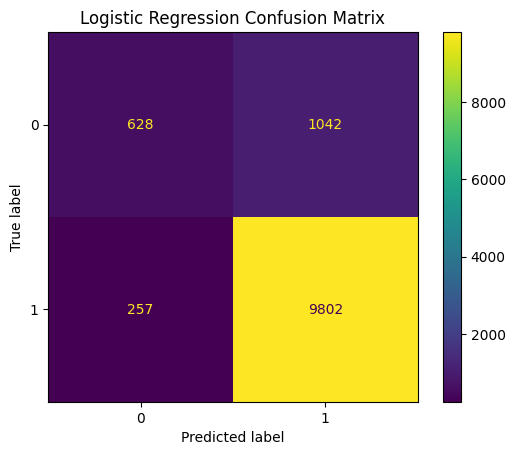

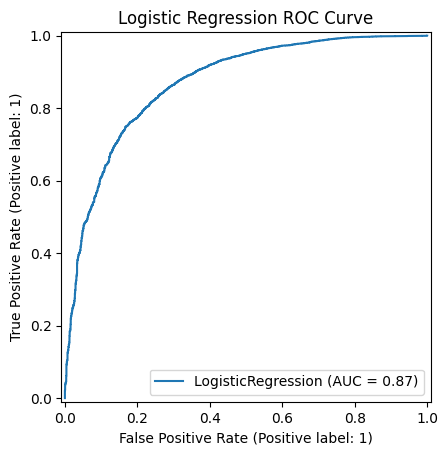

In [5]:
print("Logistic Regression Classification Report")
print(classification_report(y_test, y_pred_lr))

lr_cm = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(lr_cm).plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

RocCurveDisplay.from_estimator(lr, X_test, y_test)
plt.title("Logistic Regression ROC Curve")
plt.show()

This section evaluates Naive Bayes.



Naive Bayes Classification Report
              precision    recall  f1-score   support

           0       0.70      0.22      0.34      1670
           1       0.88      0.98      0.93     10059

    accuracy                           0.88     11729
   macro avg       0.79      0.60      0.63     11729
weighted avg       0.86      0.88      0.85     11729



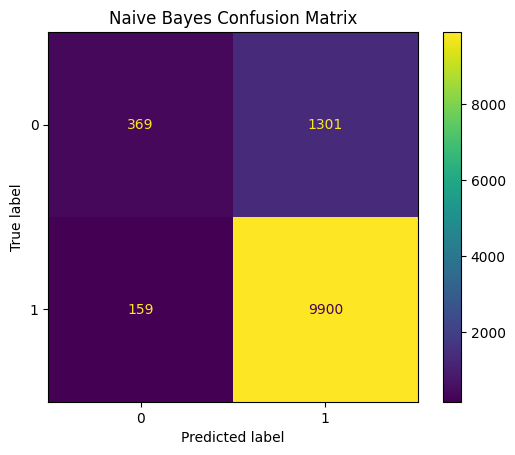

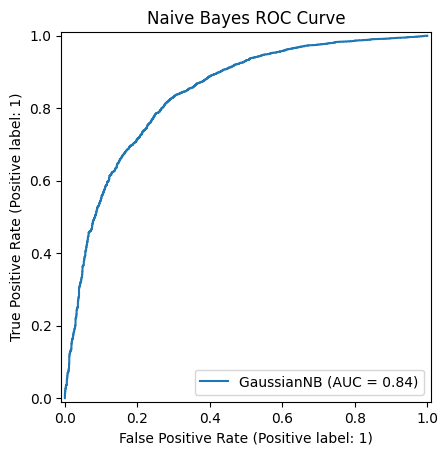

In [6]:
print("Naive Bayes Classification Report")
print(classification_report(y_test, y_pred_nb))

nb_cm = confusion_matrix(y_test, y_pred_nb)
ConfusionMatrixDisplay(nb_cm).plot()
plt.title("Naive Bayes Confusion Matrix")
plt.show()

RocCurveDisplay.from_estimator(nb, X_test, y_test)
plt.title("Naive Bayes ROC Curve")
plt.show()

This section builds a probability-based voting ensemble learner using soft voting.

Code reused from Tutorial 7: Ensemble Learning.

In [7]:
ensemble_model = VotingClassifier(
    estimators=[('lr', lr), ('nb', nb)],
    voting='soft'
)

ensemble_model.fit(X_train, y_train)
y_pred_ensemble = ensemble_model.predict(X_test)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


This section evaluates the voting ensemble learner.


Voting Ensemble Classification Report
              precision    recall  f1-score   support

           0       0.80      0.29      0.43      1670
           1       0.89      0.99      0.94     10059

    accuracy                           0.89     11729
   macro avg       0.85      0.64      0.68     11729
weighted avg       0.88      0.89      0.87     11729



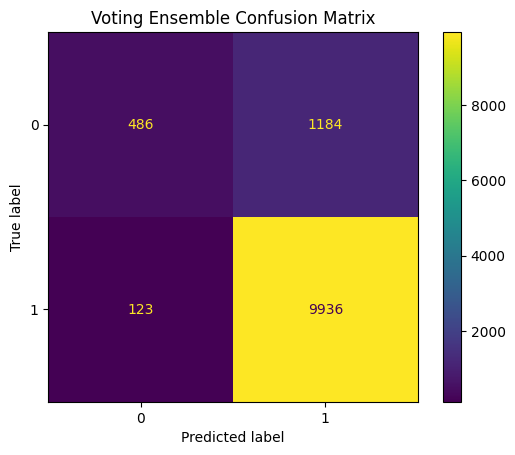

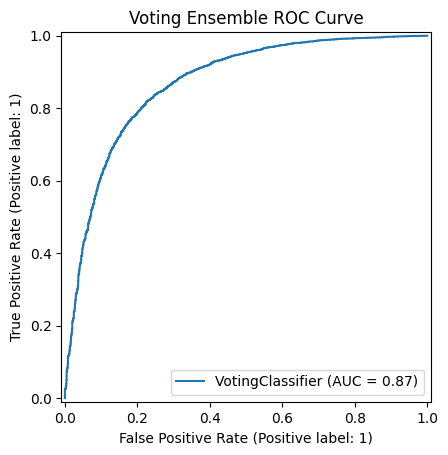

In [8]:
print("Voting Ensemble Classification Report")
print(classification_report(y_test, y_pred_ensemble))

ensemble_cm = confusion_matrix(y_test, y_pred_ensemble)
ConfusionMatrixDisplay(ensemble_cm).plot()
plt.title("Voting Ensemble Confusion Matrix")
plt.show()

RocCurveDisplay.from_estimator(ensemble_model, X_test, y_test)
plt.title("Voting Ensemble ROC Curve")
plt.show()

Case Study B: Maximum Loan Amount Regression

This section builds two Decision Tree regression models:
- DT-1 fully grown
- DT-2 pruned to four levels only

Code reused from Tutorial 6: Decision Tree Regression.

In [9]:
from sklearn.tree import DecisionTreeRegressor
from sklearn import tree
from sklearn import metrics
import numpy as np

This section loads the regression dataset prepared in Notebook 1.

In [11]:
df_reg = pd.read_csv("prepared_loan_applications_data.csv")
df_reg.head()

,age,sex,education_qualifications,income,home_ownership,employment_length,loan_intent,loan_amount,loan_interest_rate,loan_income_ratio,payment_default_on_file,credit_history_length,loan_approval_status,max_loan_amount(allowed),credit_application_acceptance
0,21.0,M,Unknown,12000.0,OWN,0.0,EDUCATION,15000,6.99,0.12,N,4,approved,-2426900,0.0
1,21.0,M,Unknown,13200.0,OWN,2.0,EDUCATION,25000,16.77,0.19,Y,3,approved,-111739,0.0
2,23.0,M,Unknown,9600.0,RENT,5.0,MEDICAL,30000,12.42,0.31,N,3,approved,-89000,0.0
3,40.0,M,Unknown,182004.0,RENT,3.0,EDUCATION,35000,8.00,0.19,N,11,approved,35000,0.0
4,40.0,M,Unknown,90000.0,MORTGAGE,3.0,HOMEIMPROVEMENT,35000,12.42,0.39,N,14,approved,35000,0.0


This section defines the regression inputs and target output.

Code reused from Tutorial 6.

In [15]:
X_reg = df_reg.drop(['max_loan_amount(allowed)'], axis=1)
y_reg = df_reg['max_loan_amount(allowed)']

X_reg = pd.get_dummies(X_reg)
X_reg = X_reg.fillna(0)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.1, random_state=10
)

print("Regression X shape:", X_reg.shape)
print("Regression y shape:", y_reg.shape)
print(X_reg.columns)

Regression X shape: (58645, 36)
Regression y shape: (58645,)
Index(['age', 'income', 'employment_length', 'loan_amount',
       'loan_interest_rate', 'loan_income_ratio', 'credit_history_length',
       'credit_application_acceptance', 'sex_F', 'sex_Female', 'sex_M',
       'sex_Male', 'education_qualifications_Apprenticeship ',
       'education_qualifications_College',
       'education_qualifications_High School',
       'education_qualifications_Higher Education',
       'education_qualifications_Unknown', 'education_qualifications_Unknown ',
       'home_ownership_MORTGAGE', 'home_ownership_OTHER', 'home_ownership_OWN',
       'home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION',
       'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT',
       'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE',
       'payment_default_on_file_N', 'payment_default_on_file_NO',
       'payment_default_on_file_Y', 'payment_default_on_file_YES',
       'loan_approval_status_ac

This section builds DT-1, the fully grown regression tree.

Code reused from Tutorial 7-8-9.

In [16]:
regressor = DecisionTreeRegressor()
regressor.fit(X_train_reg, y_train_reg)

y_pred = regressor.predict(X_test_reg)

print("The full Regression Decision Tree Levels:", regressor.tree_.max_depth)

The full Regression Decision Tree Levels: 29


This section builds DT-2, the pruned regression tree with a maximum depth of 4.

Code reused from Tutorial 7-8.

In [17]:
pruned_regressor = DecisionTreeRegressor(max_depth=4)
pruned_regressor.fit(X_train_reg, y_train_reg)

y_pred_pruned = pruned_regressor.predict(X_test_reg)

This section visualises DT-1 and DT-2.


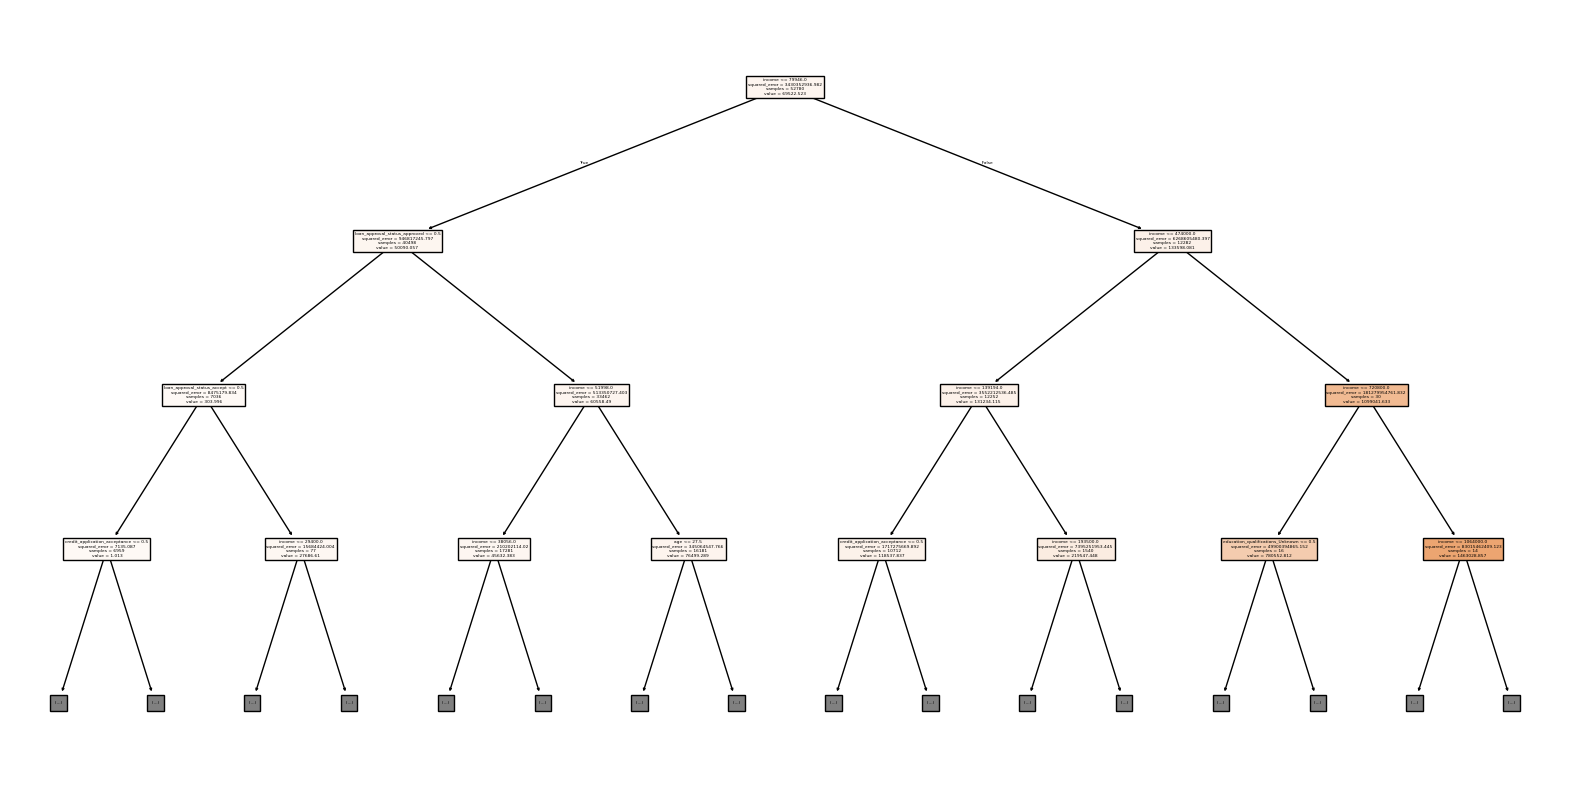

In [20]:
plt.figure(figsize=(20,10))
tree.plot_tree(regressor, max_depth=3, feature_names=list(X_train_reg.columns), filled=True)
plt.show()

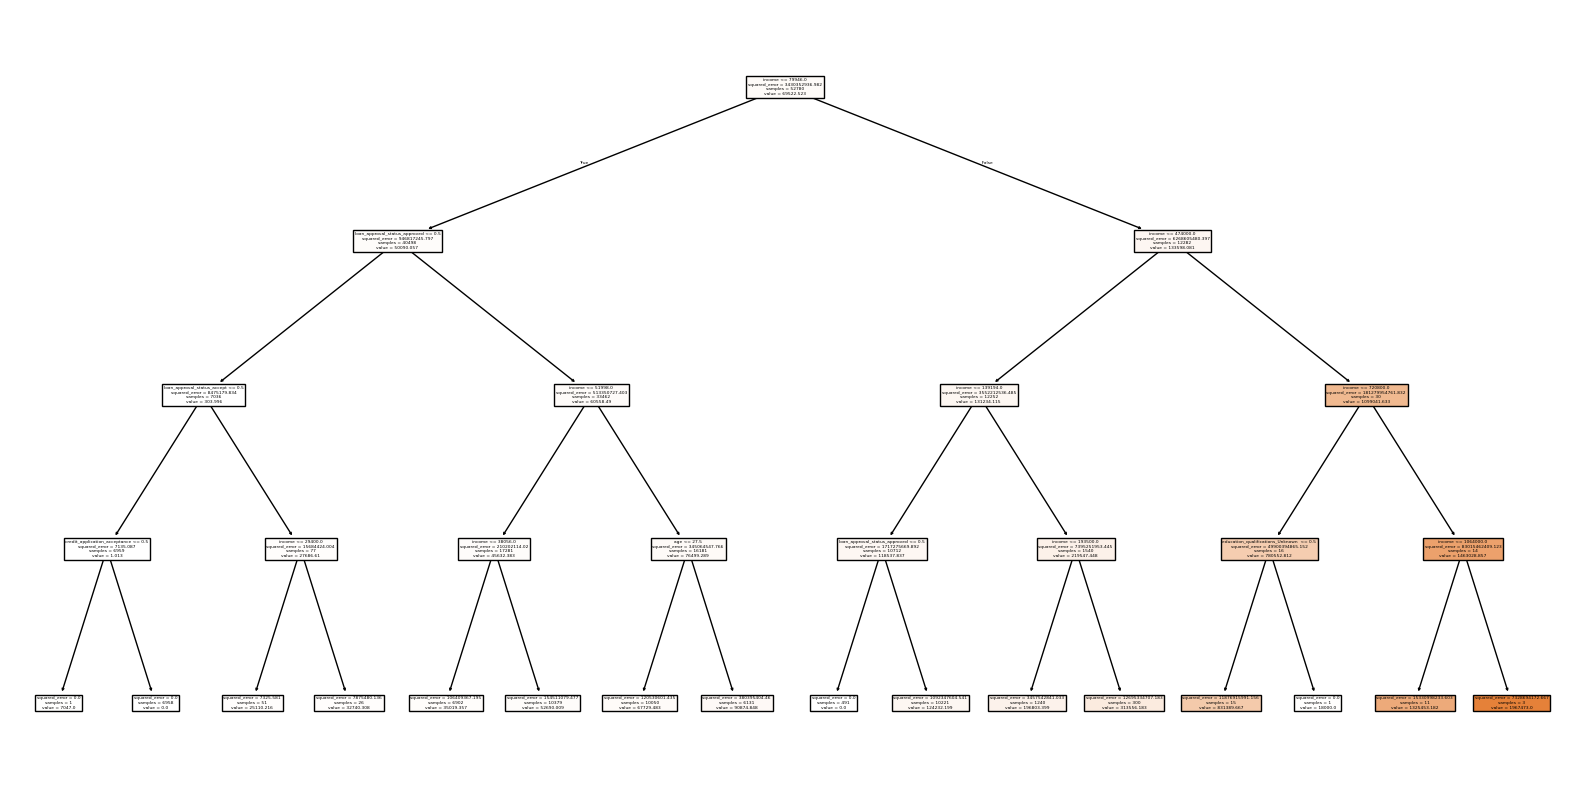

In [21]:
plt.figure(figsize=(20, 10))
tree.plot_tree(pruned_regressor, feature_names=list(X_train_reg.columns), filled=True)
plt.show()

This section calculates regression metrics for DT-1 and DT-2.

Code reused from Tutorial 6.

In [22]:
print("DT-1 Fully Grown")
print("Mean Absolute Error:", metrics.mean_absolute_error(y_test_reg, y_pred))
print("Mean Squared Error:", metrics.mean_squared_error(y_test_reg, y_pred))
print("Root Mean Squared Error:", np.sqrt(metrics.mean_squared_error(y_test_reg, y_pred)))
print("R2:", metrics.r2_score(y_test_reg, y_pred))

DT-1 Fully Grown
Mean Absolute Error: 2127591.3502131286
Mean Squared Error: 2.650433598970875e+16
Root Mean Squared Error: 162801523.30278963
R2: -0.00016353949504854803


In [23]:
print("DT-2 Pruned")
print("Mean Absolute Error:", metrics.mean_absolute_error(y_test_reg, y_pred_pruned))
print("Mean Squared Error:", metrics.mean_squared_error(y_test_reg, y_pred_pruned))
print("Root Mean Squared Error:", np.sqrt(metrics.mean_squared_error(y_test_reg, y_pred_pruned)))
print("R2:", metrics.r2_score(y_test_reg, y_pred_pruned))

DT-2 Pruned
Mean Absolute Error: 2139641.7145340834
Mean Squared Error: 2.650429293090754e+16
Root Mean Squared Error: 162801391.05949783
R2: -0.00016191463476000756


Peer Review

Reviewer/group: Muller Zerufael / Timeout
Date: 23/03/26

Checks:
- Regression dataset loaded correctly
- Input and target variables defined correctly
- DT-1 fully grown regressor built successfully
- DT-2 pruned regressor built with max_depth = 4
- Regression trees visualised successfully
- MAE, MSE and R2 metrics calculated for both models

Result:
The regression section executed successfully and produced both decision tree models and their evaluation metrics. The pruned tree was simpler and easier to interpret, while the fully grown tree captured more detailed patterns.

task 3d

In [24]:
client = pd.DataFrame([{
    'age': 56,
    'income': 57000,
    'home_ownership': 'RENT',
    'employment_length': 15,
    'loan_intent': 'MEDICAL',
    'loan_amount': 25700,
    'loan_interest_rate': 23,
    'loan_percent_income': 10,
    'credit_history_length': 35,
    'loan_status': 'Approved'
}])

client = pd.get_dummies(client)
client = client.reindex(columns=X_train_reg.columns, fill_value=0)

prediction = pruned_regressor.predict(client)
print(prediction)

[7047.]
